# 7. Model Comparison

Logistic Regression vs. Random Forest vs. XGBoost across feature-availability scenarios, per-class recall, and stratified 5-fold cross-validation (7.3 for Full Data; 7.4-7.5 for every information stage).

Loads the results tables saved by notebooks 3, 4, and 5 (run those first); refits all models once more on Full Data (same split, via `evaluate_feature_set`) to get a matched pair of predictions for the per-class recall comparison in 7.2.

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd if (cwd / "requirements.txt").exists() else cwd.parent
sys.path.append(str(project_root))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.evaluate import (
    cross_validate_xgboost,
    evaluate_feature_set,
    evaluate_xgboost_feature_set,
)
from src.models import (
    get_logistic_regression,
    get_random_forest,
)
from src.plotting import MODEL_ORDER, MODEL_PALETTE
from src.preprocessing import (
    TARGET_COL,
    build_model_pipeline,
    get_feature_availability_sets,
    load_data,
)

sns.set_theme(style="whitegrid")
df = load_data()
feature_sets = get_feature_availability_sets(df)

feature_results_df = pd.read_csv(project_root / "data" / "processed" / "logreg_feature_availability.csv")
rf_feature_results_df = pd.read_csv(project_root / "data" / "processed" / "rf_feature_availability.csv")
xgb_feature_results_df = pd.read_csv(project_root / "data" / "processed" / "xgb_feature_availability.csv")

## 7.1 Logistic Regression vs. Random Forest vs. XGBoost across feature availability

In [3]:
logreg_compare = feature_results_df.copy()
logreg_compare["Model"] = "Logistic Regression"

rf_compare = rf_feature_results_df.copy()
rf_compare["Model"] = "Random Forest"

xgb_compare = xgb_feature_results_df.copy()
xgb_compare["Model"] = "XGBoost"

all_model_results = pd.concat([logreg_compare, rf_compare, xgb_compare], ignore_index=True)
display(all_model_results.round(3))


,Feature Set,Accuracy,Macro F1,Dropout Recall,Enrolled Recall,Graduate Recall,Model,Macro Recall
0,Day 1,0.573,0.550,0.577,0.522,0.588,Logistic Regression,NaN
1,After Semester 1,0.698,0.658,0.683,0.560,0.758,Logistic Regression,NaN
2,Full Data,0.725,0.689,0.680,0.635,0.787,Logistic Regression,NaN
3,Day 1,0.612,0.539,0.627,0.258,0.731,Random Forest,NaN
4,After Semester 1,0.716,0.647,0.697,0.390,0.846,Random Forest,NaN
5,Full Data,0.763,0.713,0.718,0.547,0.869,Random Forest,NaN
6,Day 1,0.592,0.561,0.570,0.497,0.640,XGBoost,0.569
7,After Semester 1,0.705,0.667,0.648,0.616,0.774,XGBoost,0.679
8,Full Data,0.737,0.702,0.694,0.660,0.792,XGBoost,0.715


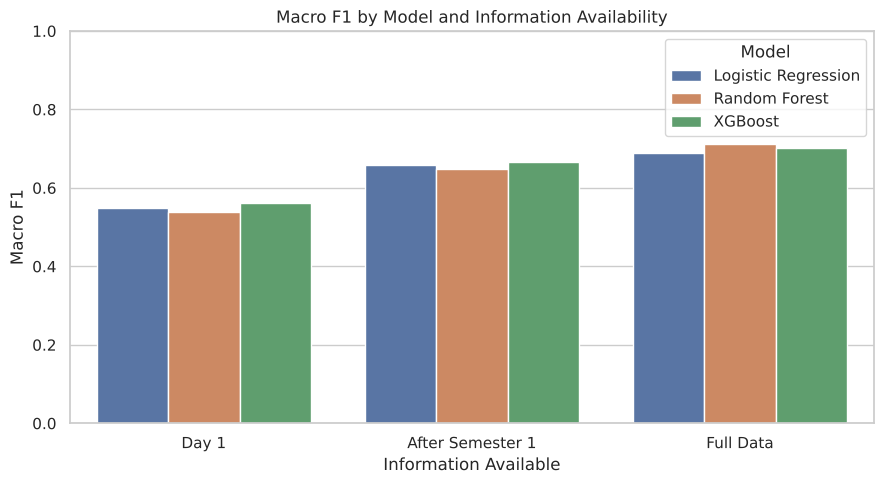

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=all_model_results, x="Feature Set", y="Macro F1", hue="Model", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Macro F1 by Model and Information Availability")
ax.set_xlabel("Information Available")
ax.set_ylabel("Macro F1")
plt.tight_layout()
plt.show()


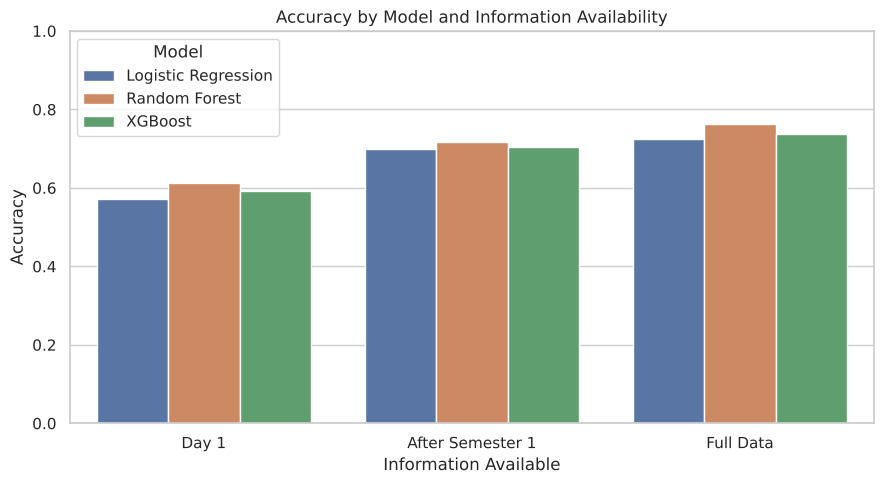

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=all_model_results, x="Feature Set", y="Accuracy", hue="Model", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Accuracy by Model and Information Availability")
ax.set_xlabel("Information Available")
ax.set_ylabel("Accuracy")
plt.tight_layout()
plt.show()


## 7.2 Per-class recall

Refits all models once on Full Data (same 80/20 split, since `evaluate_feature_set` uses the same `random_state`) to obtain directly comparable per-class recall.

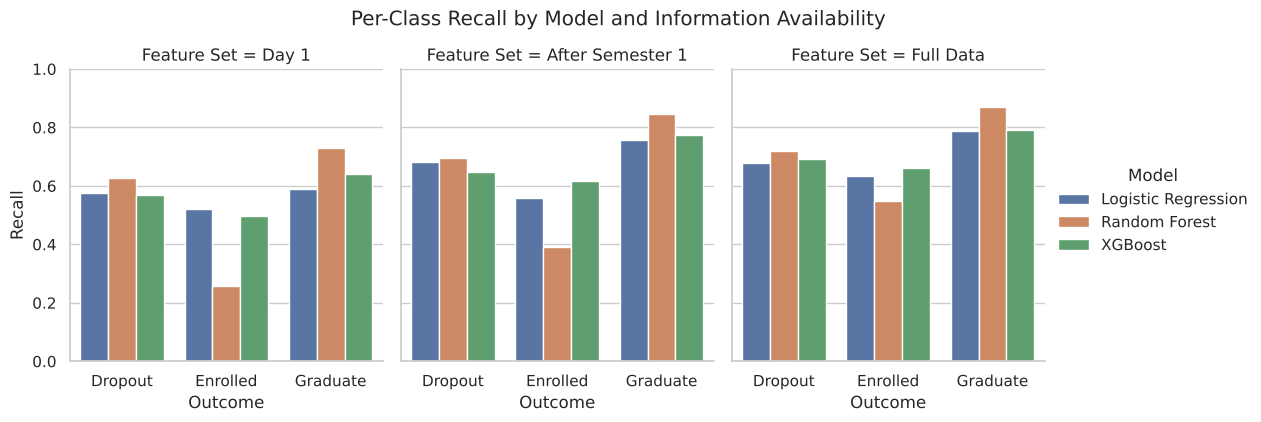

In [6]:
recall_long = all_model_results.melt(
    id_vars=["Feature Set", "Model"],
    value_vars=["Dropout Recall", "Enrolled Recall", "Graduate Recall"],
    var_name="Outcome", value_name="Recall"
)
recall_long["Outcome"] = recall_long["Outcome"].str.replace(" Recall", "", regex=False)

g = sns.catplot(
    data=recall_long, x="Outcome", y="Recall", hue="Model", col="Feature Set",
    kind="bar", height=4, aspect=0.9
)
g.set(ylim=(0, 1))
g.set_axis_labels("Outcome", "Recall")
g.fig.suptitle("Per-Class Recall by Model and Information Availability", y=1.05)
plt.show()


In [7]:
classes = ["Dropout", "Enrolled", "Graduate"]

_, _, X_test_lr, y_test_lr, y_pred_lr = evaluate_feature_set(
    df, feature_sets["Full Data"], "Full Data", get_logistic_regression(),
    scale_numeric=True, return_split=True
)
_, _, X_test_rf, y_test_rf, y_pred_rf = evaluate_feature_set(
    df, feature_sets["Full Data"], "Full Data", get_random_forest(),
    scale_numeric=False, return_split=True
)

_, _, X_test_xgb, y_test_xgb, y_pred_xgb = evaluate_xgboost_feature_set(
    df=df, feature_cols=feature_sets["Full Data"], feature_set_name="Full Data", return_split=True
)

logreg_class_recall = recall_score(y_test_lr, y_pred_lr, labels=classes, average=None)
rf_class_recall = recall_score(y_test_rf, y_pred_rf, labels=classes, average=None)
xgb_class_recall = recall_score(y_test_xgb, y_pred_xgb, labels=classes, average=None)

recall_comparison = pd.DataFrame({
    "Class": classes,
    "Logistic Regression": logreg_class_recall,
    "Random Forest": rf_class_recall,
    "XGBoost": xgb_class_recall
})

display(recall_comparison.round(3))

,Class,Logistic Regression,Random Forest,XGBoost
0,Dropout,0.683,0.718,0.694
1,Enrolled,0.635,0.547,0.660
2,Graduate,0.787,0.869,0.792


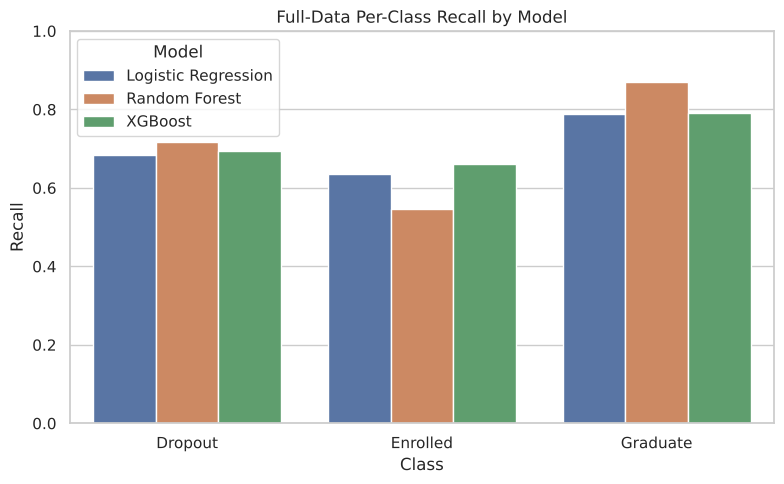

In [8]:
recall_comparison_long = recall_comparison.melt(id_vars="Class", var_name="Model", value_name="Recall")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=recall_comparison_long, x="Class", y="Recall", hue="Model", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Full-Data Per-Class Recall by Model")
plt.tight_layout()
plt.show()


## 7.3 Stratified 5-fold cross-validation

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro", "macro_recall": "recall_macro"}

full_cols = feature_sets["Full Data"]
X_cv = df[full_cols]
y_cv = df[TARGET_COL]

logreg_cv_pipe = build_model_pipeline(get_logistic_regression(random_state=42), full_cols, scale_numeric=True)
logreg_cv_results = cross_validate(logreg_cv_pipe, X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=-1)

rf_cv_pipe = build_model_pipeline(get_random_forest(random_state=42), full_cols, scale_numeric=False)
rf_cv_results = cross_validate(rf_cv_pipe, X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=-1)

xgb_cv_results = cross_validate_xgboost(
    df=df,
    feature_cols=full_cols,
    feature_set_name="Full Data",
    n_splits=5,
    random_state=42
)

cv_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Mean Accuracy": [
        logreg_cv_results["test_accuracy"].mean(),
        rf_cv_results["test_accuracy"].mean(),
        xgb_cv_results["Accuracy"].mean()
    ],

    "SD Accuracy": [
        logreg_cv_results["test_accuracy"].std(),
        rf_cv_results["test_accuracy"].std(),
        xgb_cv_results["Accuracy"].std()
    ],

    "Mean Macro F1": [
        logreg_cv_results["test_macro_f1"].mean(),
        rf_cv_results["test_macro_f1"].mean(),
        xgb_cv_results["Macro F1"].mean()
    ],

    "SD Macro F1": [
        logreg_cv_results["test_macro_f1"].std(),
        rf_cv_results["test_macro_f1"].std(),
        xgb_cv_results["Macro F1"].std()
    ],

    "Mean Macro Recall": [
        logreg_cv_results["test_macro_recall"].mean(),
        rf_cv_results["test_macro_recall"].mean(),
        xgb_cv_results["Macro Recall"].mean()
    ],

    "SD Macro Recall": [
        logreg_cv_results["test_macro_recall"].std(),
        rf_cv_results["test_macro_recall"].std(),
        xgb_cv_results["Macro Recall"].std()
    ]
})

display(cv_comparison.round(3))


,Model,Mean Accuracy,SD Accuracy,Mean Macro F1,SD Macro F1,Mean Macro Recall,SD Macro Recall
0,Logistic Regression,0.749,0.016,0.709,0.016,0.717,0.015
1,Random Forest,0.773,0.011,0.716,0.012,0.709,0.012
2,XGBoost,0.762,0.006,0.722,0.003,0.729,0.005


In [10]:
for _, row in cv_comparison.iterrows():
    print(row["Model"])

    print(
        f"  Accuracy: "
        f"{row['Mean Accuracy']:.3f} +/- "
        f"{row['SD Accuracy']:.3f}"
    )

    print(
        f"  Macro F1: "
        f"{row['Mean Macro F1']:.3f} +/- "
        f"{row['SD Macro F1']:.3f}"
    )

    print(
        f"  Macro Recall: "
        f"{row['Mean Macro Recall']:.3f} +/- "
        f"{row['SD Macro Recall']:.3f}"
    )

    print()


Logistic Regression
  Accuracy: 0.749 +/- 0.016
  Macro F1: 0.709 +/- 0.016
  Macro Recall: 0.717 +/- 0.015

Random Forest
  Accuracy: 0.773 +/- 0.011
  Macro F1: 0.716 +/- 0.012
  Macro Recall: 0.709 +/- 0.012

XGBoost
  Accuracy: 0.762 +/- 0.006
  Macro F1: 0.722 +/- 0.003
  Macro Recall: 0.729 +/- 0.005



## 7.4 Cross-validation at every information stage

7.1 compares the models on a single 80/20 split, and 7.3 cross-validates only Full Data. Here every model is cross-validated at **every** stage on the same 5 folds as 7.3, so each point has a spread and the models can be compared fairly at Day 1 and After Semester 1 too.

In [11]:
CLASSES = ["Dropout", "Enrolled", "Graduate"]
STAGES = ["Day 1", "After Semester 1", "Full Data"]
stage_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    **{c: make_scorer(recall_score, labels=[c], average="macro") for c in CLASSES},
}

stage_rows = []
for stage in STAGES:
    cols = feature_sets[stage]
    for model_name, make_model, scale in [
        ("Logistic Regression", get_logistic_regression, True),
        ("Random Forest", get_random_forest, False),
    ]:
        res = cross_validate(build_model_pipeline(make_model(random_state=42), cols, scale_numeric=scale),
                             df[cols], df[TARGET_COL], cv=cv, scoring=stage_scoring, n_jobs=-1)
        stage_rows.append({"Stage": stage, "Model": model_name,
                           "Macro F1": res["test_macro_f1"].mean(), "SD Macro F1": res["test_macro_f1"].std(),
                           "Accuracy": res["test_accuracy"].mean(),
                           **{f"{c} Recall": res[f"test_{c}"].mean() for c in CLASSES}})
    xgb_res = cross_validate_xgboost(df=df, feature_cols=cols, feature_set_name=stage, n_splits=5, random_state=42)
    stage_rows.append({"Stage": stage, "Model": "XGBoost",
                       "Macro F1": xgb_res["Macro F1"].mean(), "SD Macro F1": xgb_res["Macro F1"].std(),
                       "Accuracy": xgb_res["Accuracy"].mean(),
                       **{f"{c} Recall": xgb_res[f"{c} Recall"].mean() for c in CLASSES}})

cv_by_stage = pd.DataFrame(stage_rows)
cv_by_stage.to_csv(project_root / "data" / "processed" / "model_cv_by_stage.csv", index=False)
display(cv_by_stage.round(3))

,Stage,Model,Macro F1,SD Macro F1,Accuracy,Dropout Recall,Enrolled Recall,Graduate Recall
0,Day 1,Logistic Regression,0.564,0.013,0.599,0.595,0.482,0.643
1,Day 1,Random Forest,0.569,0.011,0.640,0.647,0.295,0.759
2,Day 1,XGBoost,0.578,0.019,0.613,0.564,0.519,0.680
3,After Semester 1,Logistic Regression,0.675,0.015,0.718,0.704,0.552,0.787
4,After Semester 1,Random Forest,0.673,0.016,0.740,0.723,0.411,0.870
5,After Semester 1,XGBoost,0.689,0.013,0.731,0.685,0.588,0.812
6,Full Data,Logistic Regression,0.709,0.016,0.749,0.734,0.607,0.809
7,Full Data,Random Forest,0.716,0.012,0.773,0.744,0.489,0.895
8,Full Data,XGBoost,0.722,0.003,0.762,0.722,0.628,0.836


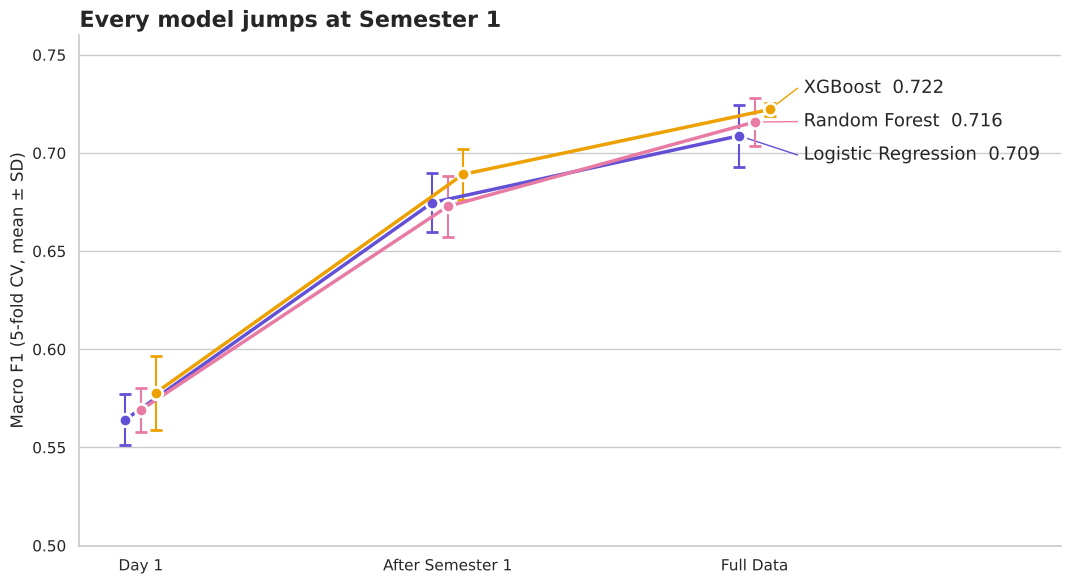

In [12]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(STAGES))
label_y = {"XGBoost": 0.733, "Random Forest": 0.716, "Logistic Regression": 0.699}  # spaced so labels don't overlap
for model_name, dx in zip(MODEL_ORDER, [-0.05, 0, 0.05]):
    sub = cv_by_stage[cv_by_stage["Model"] == model_name].set_index("Stage").loc[STAGES]
    color = MODEL_PALETTE[model_name]
    ax.errorbar(x + dx, sub["Macro F1"], yerr=sub["SD Macro F1"], color=color, lw=2.5, marker="o",
                ms=9, capsize=4, mec="white", mew=2, elinewidth=1.5)
    ax.plot([2 + dx, 2.14], [sub["Macro F1"].iloc[-1], label_y[model_name]], color=color, lw=1)
    ax.text(2.16, label_y[model_name], f"{model_name}  {sub['Macro F1'].iloc[-1]:.3f}", va="center", fontsize=13)

ax.set_xticks(x, STAGES)
ax.set_xlim(-0.2, 3.0)
ax.set_ylim(0.5, 0.76)
ax.set_ylabel("Macro F1 (5-fold CV, mean ± SD)")
ax.set_title("Every model jumps at Semester 1", loc="left", fontsize=16, fontweight="bold")
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(project_root / "reports" / "figures" / "model_macro_f1_by_stage_cv.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
gains = cv_by_stage.pivot(index="Model", columns="Stage", values="Macro F1")[STAGES]
gains["Gain from Semester 1"] = gains["After Semester 1"] - gains["Day 1"]
gains["Gain from Semester 2"] = gains["Full Data"] - gains["After Semester 1"]
display(gains.round(3))

Stage,Day 1,After Semester 1,Full Data,Gain from Semester 1,Gain from Semester 2
Model,,,,,
Logistic Regression,0.564,0.675,0.709,0.111,0.034
Random Forest,0.569,0.673,0.716,0.104,0.043
XGBoost,0.578,0.689,0.722,0.111,0.033


**Reading this:**

- **All three models make the same jump.** Adding Semester 1 data raises macro F1 by about **+0.10 to +0.11** for every model; Semester 2 adds only about **+0.03 to +0.04** more.
- **The model matters much less than the information.** At any stage the three models are within about 0.016 of each other, roughly one fold-to-fold standard deviation. XGBoost is on top at every stage, but the error bars overlap, so it isn't a clear winner.
- The single-split numbers in 7.1 are a little lower than these CV means (the test split happens to be slightly harder than average), which is why comparisons should use CV.

## 7.5 Where each model's accuracy comes from: per-class recall (CV, Full Data)

Random Forest has the highest accuracy in 7.3. This shows which outcomes it gets right, and which it gives up, to get there.

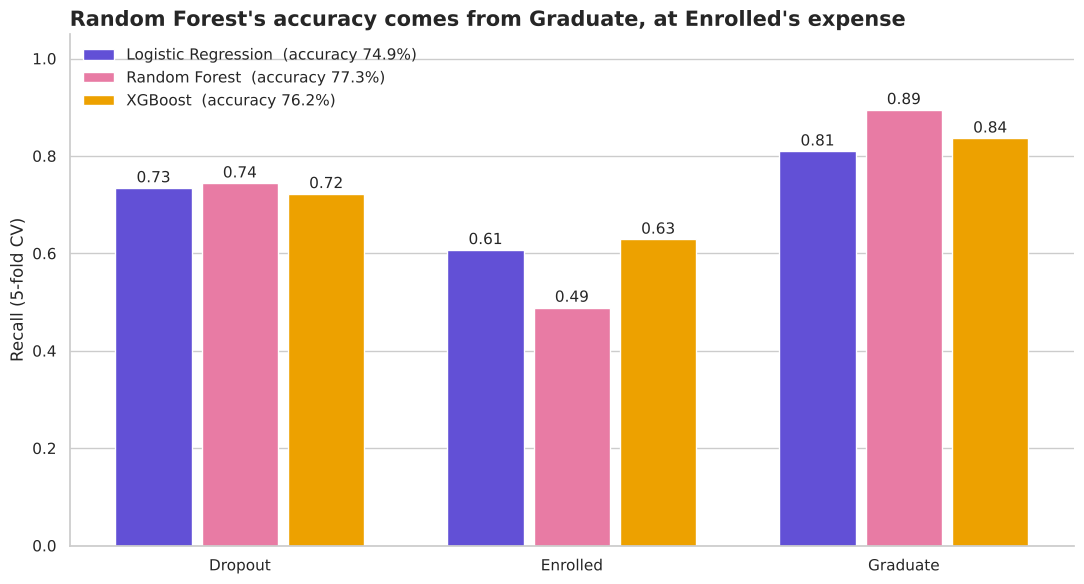

In [14]:
full_cv = cv_by_stage[cv_by_stage["Stage"] == "Full Data"].set_index("Model")
width = 0.26
fig, ax = plt.subplots(figsize=(11, 6))
for i, model_name in enumerate(MODEL_ORDER):
    vals = full_cv.loc[model_name, [f"{c} Recall" for c in CLASSES]].to_numpy(dtype=float)
    bars = ax.bar(np.arange(len(CLASSES)) + (i - 1) * width, vals, width=width - 0.03,
                  color=MODEL_PALETTE[model_name],
                  label=f"{model_name}  (accuracy {full_cv.loc[model_name, 'Accuracy']:.1%})")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}", ha="center", fontsize=11)

ax.set_xticks(np.arange(len(CLASSES)), CLASSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall (5-fold CV)")
ax.set_title("Random Forest's accuracy comes from Graduate, at Enrolled's expense",
             loc="left", fontsize=15, fontweight="bold")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(project_root / "reports" / "figures" / "model_per_class_recall_cv.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
# Is Random Forest's low Enrolled recall specific to Full Data, or does it happen at every stage?
display(cv_by_stage.pivot(index="Model", columns="Stage", values="Enrolled Recall")[STAGES].round(3))

Stage,Day 1,After Semester 1,Full Data
Model,,,
Logistic Regression,0.482,0.552,0.607
Random Forest,0.295,0.411,0.489
XGBoost,0.519,0.588,0.628


**Reading this:**

- **Random Forest buys its accuracy with Graduate.** It has the highest Graduate recall but the lowest Enrolled recall, and the Enrolled gap appears at **every** information stage, so it's systematic rather than a fluke of one split.
- **XGBoost is the most balanced** (highest Enrolled recall and macro F1), and **Logistic Regression is close behind** while staying interpretable.
- On macro F1 the three models are statistically tied: `assumptions_checks.ipynb` (section 5) finds Random Forest's macro-F1 edge over Logistic Regression is not significant (corrected resampled t-test, p ≈ 0.19), while its accuracy edge is (p ≈ 0.002).

**Conjectures:**

- *Why trees edge out Logistic Regression on accuracy:* some effects aren't straight lines. Age at enrollment fails the Box-Tidwell linearity test (`assumptions_checks` 3.2): dropout risk jumps between 18 and 25 and then flattens, which a tree captures with a single split.
- *Why Random Forest neglects Enrolled:* its trees are grown until the leaves are pure, so `class_weight="balanced"` barely changes where the splits go, and the large Graduate class dominates. Limiting leaf size (e.g. `min_samples_leaf`) is a natural next test.

**Takeaway:** for an early-warning system, accuracy is the wrong scoreboard. The models tie on the balanced metric, and the most accurate one is the worst at the class we most need to catch.